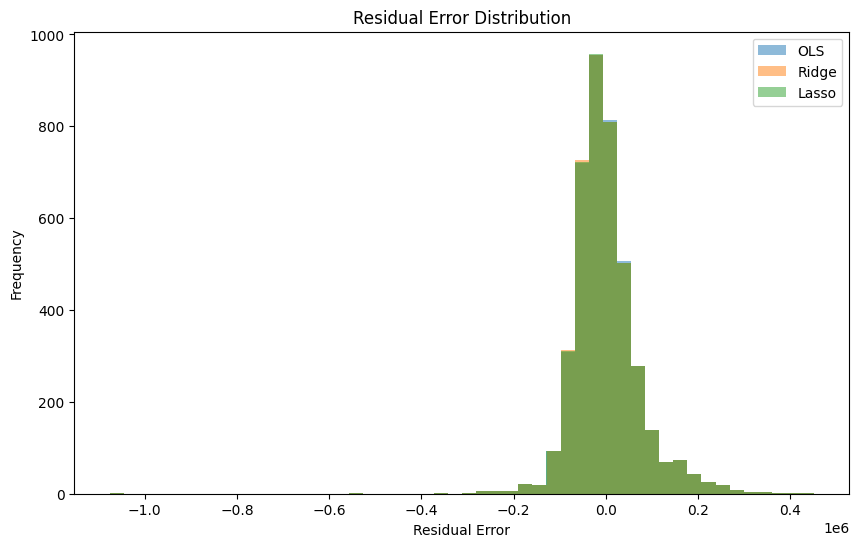

In [16]:
ols_residuals = y_test - ols_predictions
ridge_residuals = y_test - ridge_predictions
lasso_residuals = y_test - lasso_predictions

plt.figure(figsize=(10, 6))

plt.hist(ols_residuals, bins=50, alpha=0.5, label='OLS')
plt.hist(ridge_residuals, bins=50, alpha=0.5, label='Ridge')
plt.hist(lasso_residuals, bins=50, alpha=0.5, label='Lasso')

plt.xlabel('Residual Error')
plt.ylabel('Frequency')
plt.title('Residual Error Distribution')
plt.legend()
plt.show()

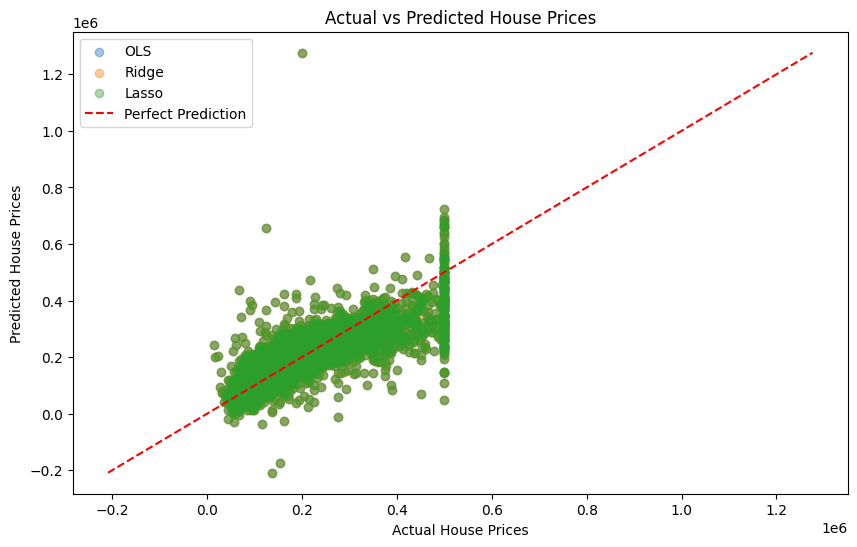

In [15]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, ols_predictions, label='OLS', alpha=0.4)
plt.scatter(y_test, ridge_predictions, label='Ridge', alpha=0.4)
plt.scatter(y_test, lasso_predictions, label='Lasso', alpha=0.4)

minimum = min(y_test.min(), ols_predictions.min(), ridge_predictions.min(), lasso_predictions.min())
maximum = max(y_test.max(), ols_predictions.max(), ridge_predictions.max(), lasso_predictions.max())

plt.plot([minimum, maximum], [minimum, maximum], 'r--', label='Perfect Prediction')

plt.xlabel('Actual House Prices')
plt.ylabel('Predicted House Prices')
plt.title('Actual vs Predicted House Prices')
plt.legend()
plt.show()

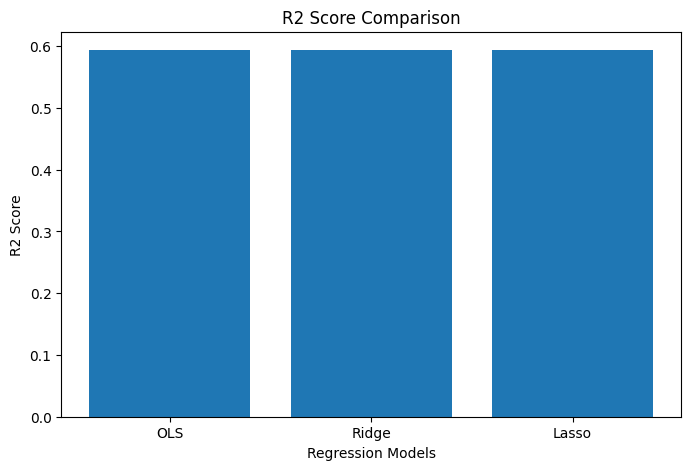

In [14]:
plt.figure(figsize=(8, 5))

plt.bar(comparison['Model'], comparison['R2 Score'])

plt.title('R2 Score Comparison')
plt.xlabel('Regression Models')
plt.ylabel('R2 Score')

plt.show()

In [13]:
comparison = pd.DataFrame({
      'Model': ['OLS', 'Ridge', 'Lasso'],
          'MAE': [ols_mae, ridge_mae, lasso_mae],
              'RMSE': [ols_rmse, ridge_rmse, lasso_rmse],
                  'R2 Score': [ols_r2, ridge_r2, lasso_r2]
                  })

comparison


,Model,MAE,RMSE,R2 Score
0,OLS,51116.282621,72977.494715,0.593584
1,Ridge,51123.553461,72984.402412,0.593507
2,Lasso,51116.765334,72977.028467,0.593589


In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ols_mae = mean_absolute_error(y_test, ols_predictions)
ols_rmse = np.sqrt(mean_squared_error(y_test, ols_predictions))
ols_r2 = r2_score(y_test, ols_predictions)

ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))
ridge_r2 = r2_score(y_test, ridge_predictions)

lasso_mae = mean_absolute_error(y_test, lasso_predictions)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_predictions))
lasso_r2 = r2_score(y_test, lasso_predictions)

print("OLS:", ols_mae, ols_rmse, ols_r2)
print("Ridge:", ridge_mae, ridge_rmse, ridge_r2)
print("Lasso:", lasso_mae, lasso_rmse, lasso_r2)

OLS: 51116.28262079208 72977.49471509377 0.5935837724463086
Ridge: 51123.55346099192 72984.40241199506 0.5935068300137372
Lasso: 51116.765334302545 72977.02846669075 0.5935889655626925


In [10]:
from sklearn.linear_model import Lasso

lasso = Lasso(max_iter=10000)

lasso_params = {'alpha': [0.01, 0.1, 1, 10, 100]}

lasso_grid = GridSearchCV(lasso, lasso_params, cv=5, scoring='neg_mean_squared_error')

lasso_grid.fit(X_train_scaled, y_train)

best_lasso = lasso_grid.best_estimator_

lasso_predictions = best_lasso.predict(X_test_scaled)

print("Best Lasso Alpha:", lasso_grid.best_params_)
print("Lasso Model Trained Successfully!")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.861e+12, tolerance: 1.755e+10
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.882e+12, tolerance: 1.779e+10
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.919e+12, tolerance: 1.763e

Best Lasso Alpha: {'alpha': 1}
Lasso Model Trained Successfully!


In [8]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

ridge = Ridge()

ridge_params = {'alpha': [0.01, 0.1, 1, 10, 100]}

ridge_grid = GridSearchCV(ridge, ridge_params, cv=5, scoring='neg_mean_squared_error')

ridge_grid.fit(X_train_scaled, y_train)

best_ridge = ridge_grid.best_estimator_

ridge_predictions = best_ridge.predict(X_test_scaled)

print("Best Ridge Alpha:", ridge_grid.best_params_)
print("Ridge Model Trained Successfully!")

Best Ridge Alpha: {'alpha': 1}
Ridge Model Trained Successfully!


In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ols_mae = mean_absolute_error(y_test, ols_predictions)

ols_rmse = np.sqrt(mean_squared_error(y_test, ols_predictions))

ols_r2 = r2_score(y_test, ols_predictions)

print("OLS MAE:", ols_mae)
print("OLS RMSE:", ols_rmse)
print("OLS R2 Score:", ols_r2)

OLS MAE: 51116.28262079208
OLS RMSE: 72977.49471509377
OLS R2 Score: 0.5935837724463086


In [6]:
from sklearn.linear_model import LinearRegression

ols_model = LinearRegression()

ols_model.fit(X_train_scaled, y_train)

ols_predictions = ols_model.predict(X_test_scaled)

print("OLS Regression Model Trained Successfully!")

OLS Regression Model Trained Successfully!


In [ ]:
xfrom sklearn.preprocessing import StandardScaler
import numpy as np

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

continuous_features = X.select_dtypes(include=np.number).columns.tolist()

continuous_features = [col for col in continuous_features if not col.startswith('ocean_proximity_')]

X_train_scaled[continuous_features] = scaler.fit_transform(X_train[continuous_features])

X_test_scaled[continuous_features] = scaler.transform(X_test[continuous_features])

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (16512, 13)
Testing data shape: (4128, 13)


In [ ]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 13)
X_test: (4128, 13)
y_train: (16512,)
y_test: (4128,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
        test_size=0.2,
            random_state=42
            )

In [ ]:
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

In [ ]:
correlation['median_house_value'].sort_values(
      ascending=False
      )


,median_house_value
median_house_value,1.000000
median_income,0.688075
income_rooms_interaction,0.555438
rooms_per_household,0.151948
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049686
population_per_household,-0.023737
population,-0.024650


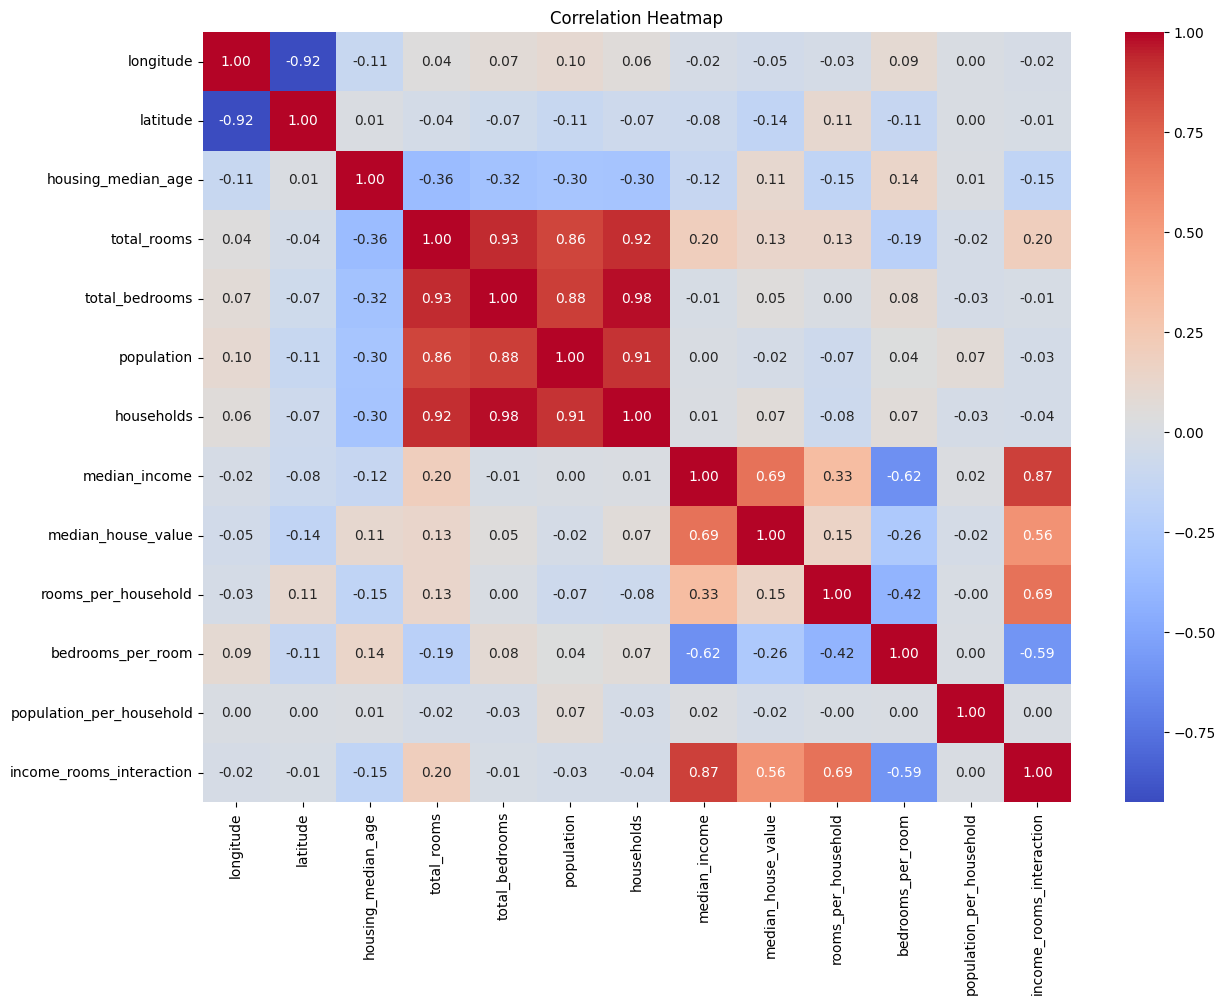

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
        annot=True,
            cmap='coolwarm',
                fmt='.2f'
                )

plt.title('Correlation Heatmap')
plt.show()

In [ ]:
correlation = df.corr(numeric_only=True)

correlation

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,rooms_per_household,bedrooms_per_room,population_per_household,income_rooms_interaction
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967,-0.027540,0.092657,0.002476,-0.015430
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160,0.106389,-0.113815,0.002366,-0.011546
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623,-0.153277,0.136089,0.013191,-0.151144
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153,0.133798,-0.187900,-0.024581,0.195641
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686,0.001538,0.084238,-0.028355,-0.008846
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650,-0.072213,0.035319,0.069863,-0.030640
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843,-0.080598,0.065087,-0.027309,-0.035290
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075,0.326895,-0.615661,0.018766,0.869603
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000,0.151948,-0.255880,-0.023737,0.555438
rooms_per_household,-0.027540,0.106389,-0.153277,0.133798,0.001538,-0.072213,-0.080598,0.326895,0.151948,1.000000,-0.416952,-0.004852,0.689763


In [ ]:
df.shape

(20640, 14)

In [ ]:
df[['rooms_per_household',
    'bedrooms_per_room',
        'population_per_household',
            'income_rooms_interaction']].head()

,rooms_per_household,bedrooms_per_room,population_per_household,income_rooms_interaction
0,6.984127,0.146591,2.555556,58.144254
1,6.238137,0.155797,2.109842,51.785271
2,8.288136,0.129516,2.802260,60.150315
3,5.817352,0.184458,2.547945,32.827897
4,6.281853,0.172096,2.181467,24.161264


In [ ]:
df['income_rooms_interaction'] = (
      df['median_income'] * df['rooms_per_household']
      )


In [ ]:
import pandas as pd
df = pd.read_csv('/content/housing 2.csv')
# Rooms per household
df['rooms_per_household'] = (
    df['total_rooms'] / df['households']
    )

    # Bedrooms per room
df['bedrooms_per_room'] = (
        df['total_bedrooms'] / df['total_rooms']
        )

        # Population per household
df['population_per_household'] = (
            df['population'] / df['households']
            )

In [ ]:
df.shape

(20640, 14)

In [ ]:
import pandas as pd
df = pd.read_csv('/content/housing 2.csv')
df = pd.get_dummies(df, columns=['ocean_proximity'], dtype=int)

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0,0,0,1,0


In [ ]:
numerical_cols = df.select_dtypes(include=np.number).columns

categorical_cols = df.select_dtypes(include='object').columns

print("Numerical columns:", list(numerical_cols))
print("Categorical columns:", list(categorical_cols))

Numerical columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']
Categorical columns: ['ocean_proximity']


In [ ]:
df['total_bedrooms'] = df['total_bedrooms'].fillna(
      df['total_bedrooms'].median()
      )
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [ ]:
df.shape
df.columns


Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

In [ ]:
df.shape
df.columns
df.info()
df.isnull().sum()
df.describe()
df['ocean_proximity'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


In [ ]:
df = pd.read_csv('/content/housing 2.csv')

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns